In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Step 1: Load dataset
data = pd.read_csv("sales_data_sample.csv", encoding="latin1")

In [2]:
# Step 2: Select numerical columns
X = data[['SALES', 'QUANTITYORDERED', 'PRICEEACH', 'MSRP']]

# Step 3: Scale the data
sc = StandardScaler()
X = sc.fit_transform(X)


In [3]:
# Step 4: Find optimal number of clusters
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)


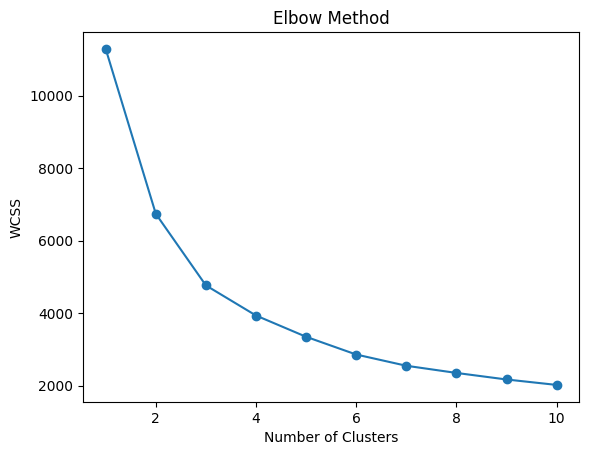

     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        1

Cluster Count:
Cluster
2    996
0    975
1    852
Name: count, dtype: int64


In [4]:

# Step 5: Plot Elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

# Step 6: Apply K-Means with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X)

# Step 7: Display result
print(data[['SALES', 'QUANTITYORDERED', 'Cluster']].head())
print("\nCluster Count:")
print(data['Cluster'].value_counts())


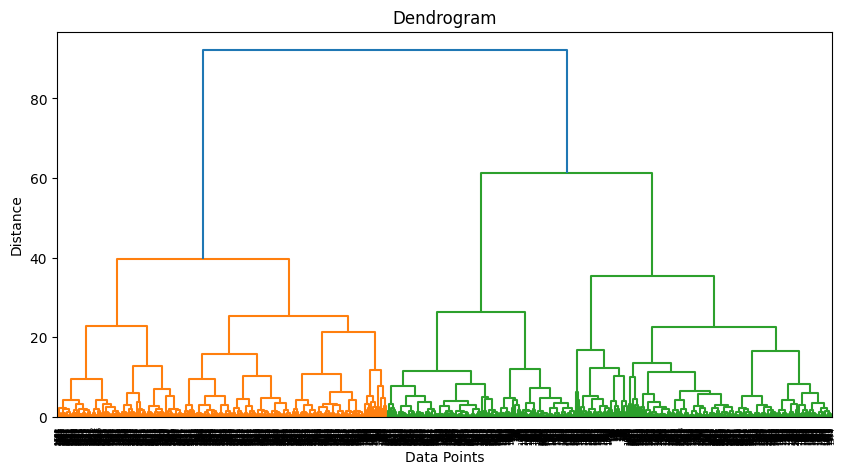

In [7]:
Z = linkage(X, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(Z)

plt.title("Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

In [8]:
#apply hierarchical clustering with 3 clusters
clusters = fcluster(Z, 3, criterion='maxclust')

data['Cluster'] = clusters

In [9]:
print(data[['SALES', 'QUANTITYORDERED', 'Cluster']].head())

print("\nCluster Count:")
print(data['Cluster'].value_counts())

     SALES  QUANTITYORDERED  Cluster
0  2871.00               30        2
1  2765.90               34        2
2  3884.34               41        1
3  3746.70               45        1
4  5205.27               49        3

Cluster Count:
Cluster
1    1204
3     934
2     685
Name: count, dtype: int64
